# Pair Programming Report
## Logistic Regression & Classification Workshop

**Group:** Final_Project_Group 2


**Workshop:** Predicting Student Pass/Fail from Study Hours

## 1. Problem Statement

The objective of this workshop is to implement
a binary Logistic Regression classifier from
scratch using Python and NumPy.

The model predicts whether a student will pass
(1) or fail (0) based on the number of hours studied.

We will implement the sigmoid function, Binary
Cross-Entropy Loss, and Gradient Descent, then
evaluate the model's performance.


## 2. Binary Classification and Logistic Regression

Binary classification is a supervised machine learning task
in which the model predicts one of two possible classes.

In this workshop, we predict whether a student will pass
or fail an examination based on study hours.

- **Input Feature (X):** Number of hours studied.
- **Target Variable (y):** Pass (1) or Fail (0).
- **Algorithm:** Logistic Regression.
- **Decision Threshold:** 0.5.

### The Sigmoid Function

The sigmoid function converts a numerical value into
a probability between 0 and 1.

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Where:

- $z = wx + b$
- $w$ represents the model weight.
- $x$ represents the input feature.
- $b$ represents the bias.

If the predicted probability is 0.5 or greater,
the model predicts Pass (1). Otherwise, it predicts Fail (0).


Total students: 19
Passed: 9
Failed: 10
Sigmoid at z=0: 0.5


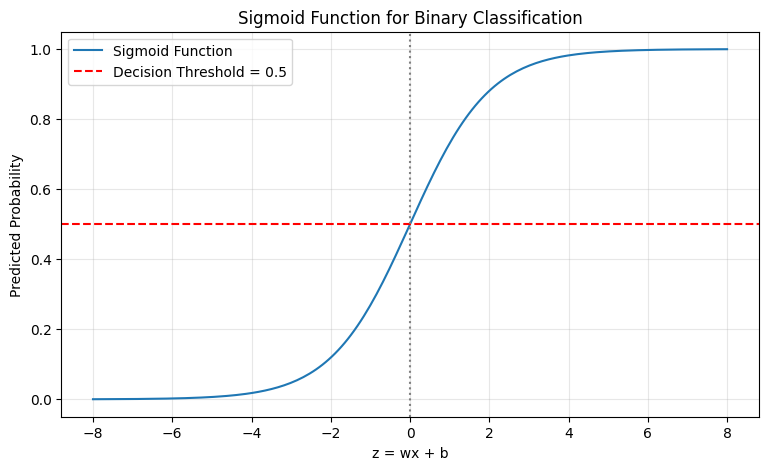

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Dataset from the professor's workshop
X = np.array([
    0.5, 0.75, 1, 1.25, 1.5,
    1.75, 2, 2.25, 2.5, 2.75,
    3, 3.25, 3.5, 3.75, 4,
    4.25, 4.5, 4.75, 5
]).reshape(-1, 1)

y = np.array([
    0, 0, 0, 0, 0,
    0, 0, 0, 1, 0,
    1, 0, 1, 1, 1,
    1, 1, 1, 1
])

# Implement the sigmoid function from scratch ( recommend (by other team ) improving  sigmoid() function)
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Display dataset information
print("Total students:", len(X))
print("Passed:", np.sum(y == 1))
print("Failed:", np.sum(y == 0))
print("Sigmoid at z=0:", sigmoid(0))

# Visualize the sigmoid function
z_values = np.linspace(-8, 8, 200)
probabilities = sigmoid(z_values)

plt.figure(figsize=(9, 5))
plt.plot(z_values, probabilities, label="Sigmoid Function")
plt.axhline(0.5, color="red", linestyle="--",
            label="Decision Threshold = 0.5")
plt.axvline(0, color="gray", linestyle=":")
plt.xlabel("z = wx + b")
plt.ylabel("Predicted Probability")
plt.title("Sigmoid Function for Binary Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



## 3. Binary Cross-Entropy (Log-Loss)

Binary Cross-Entropy is a loss function used to measure
how well a binary classification model predicts probabilities.

It compares the actual class labels (0 or 1) with the
predicted probabilities generated by the model.

### Mathematical Formula

For a single observation:

$$
L(y,p) = -[y\log(p) + (1-y)\log(1-p)]
$$

Where:

- $y$ is the actual class (0 or 1).
- $p$ is the predicted probability of class 1.
- $\log$ is the natural logarithm.

For all $m$ training observations:

$$
J(w,b) = -\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i\log(p_i) +
(1-y_i)\log(1-p_i)
\right]
$$

### Interpretation

When the actual class is 1 (Pass):

$$
L = -\log(p)
$$

When the actual class is 0 (Fail):

$$
L = -\log(1-p)
$$

A low loss indicates that the predicted probability
is close to the actual class label.

A high loss indicates an incorrect prediction,
especially when the model is very confident.

Our objective is to minimize the average
Binary Cross-Entropy using Gradient Descent.


In [2]:

# Step 3: Binary Cross-Entropy implementation

def binary_cross_entropy(y_true, y_prob):
    """
    Calculate Binary Cross-Entropy Loss using NumPy.

    Parameters:
        y_true: Actual binary labels (0 or 1)
        y_prob: Predicted probabilities of class 1

    Returns:
        Average Binary Cross-Entropy Loss
    """

    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()

    # Prevent log(0), which is undefined
    epsilon = 1e-15
    y_prob = np.clip(y_prob, epsilon, 1 - epsilon)

    # Vectorized Binary Cross-Entropy formula
    loss = -np.mean(
        y_true * np.log(y_prob)
        + (1 - y_true) * np.log(1 - y_prob)
    )

    return loss


# Example: Student actually passed
actual = np.array([1])

# Good prediction: 90% probability of passing
good_prediction = np.array([0.90])

# Bad prediction: 10% probability of passing
bad_prediction = np.array([0.10])

good_loss = binary_cross_entropy(actual, good_prediction)
bad_loss = binary_cross_entropy(actual, bad_prediction)

print(f"Good Prediction Loss: {good_loss:.4f}")
print(f"Bad Prediction Loss:  {bad_loss:.4f}")


Good Prediction Loss: 0.1054
Bad Prediction Loss:  2.3026


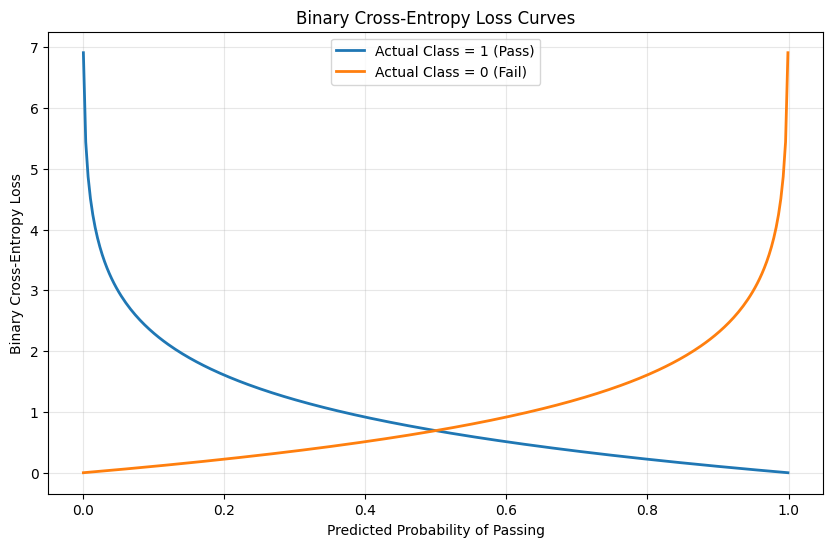

In [3]:

# Visualize Binary Cross-Entropy Loss

p = np.linspace(0.001, 0.999, 300)

# When actual class is 1 (Pass)
loss_pass = -np.log(p)

# When actual class is 0 (Fail)
loss_fail = -np.log(1 - p)

plt.figure(figsize=(10, 6))

plt.plot(
    p, loss_pass,
    label="Actual Class = 1 (Pass)",
    linewidth=2
)

plt.plot(
    p, loss_fail,
    label="Actual Class = 0 (Fail)",
    linewidth=2
)

plt.xlabel("Predicted Probability of Passing")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Binary Cross-Entropy Loss Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Results and Interpretation

The Binary Cross-Entropy function was successfully
implemented using vectorized NumPy operations.

**Experimental Results:**

- Good Prediction Loss: 0.1054
- Bad Prediction Loss: 2.3026

**Observations:**

1. When the actual outcome is Pass (1) and the model
   predicts a 90% probability of passing, the loss
   is only 0.1054.

2. When the actual outcome is Pass (1) but the model
   predicts only a 10% probability of passing,
   the loss increases to 2.3026.

3. The loss curves demonstrate that confident and
   incorrect predictions receive higher penalties.

4. Both loss curves intersect at probability 0.5,
   where the loss is approximately 0.6931.

**Conclusion:**

Binary Cross-Entropy is suitable for Logistic Regression
because it measures the difference between predicted
probabilities and actual class labels.

During model training, Gradient Descent will minimize
this loss by updating the model's weights and bias.


    
## 4. Gradient Descent for Logistic Regression

Gradient Descent is an optimization algorithm that minimizes
the Binary Cross-Entropy loss by updating the model's
weight and bias.

### Step 1: Linear Equation

For each student, calculate:

$$
z = Xw + b
$$

Where:
- $X$ = study hours
- $w$ = weight
- $b$ = bias

### Step 2: Sigmoid Prediction

Convert the linear output into a probability:

$$
p = \sigma(z) = \frac{1}{1+e^{-z}}
$$

### Step 3: Binary Cross-Entropy Loss

The average loss over $m$ observations is:

$$
J(w,b) = -\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i\log(p_i) +
(1-y_i)\log(1-p_i)
\right]
$$

### Step 4: Derive the Gradients

Using the chain rule:

$$
\frac{\partial L}{\partial p}
= -\frac{y}{p}+\frac{1-y}{1-p}
$$

The derivative of the sigmoid is:

$$
\frac{\partial p}{\partial z}=p(1-p)
$$

Therefore:

$$
\frac{\partial L}{\partial z}
= \frac{\partial L}{\partial p}
\frac{\partial p}{\partial z}
= p-y
$$

For the full dataset, the gradients are:

**Weight Gradient:**

$$
\frac{\partial J}{\partial w}
= \frac{1}{m}X^T(p-y)
$$

**Bias Gradient:**

$$
\frac{\partial J}{\partial b}
= \frac{1}{m}\sum_{i=1}^{m}(p_i-y_i)
$$

### Step 5: Update Parameters

Using a learning rate $\alpha$:

$$
w_{\text{new}}=w-\alpha\frac{\partial J}{\partial w}
$$

$$
b_{\text{new}}=b-\alpha\frac{\partial J}{\partial b}
$$

### Algorithm

1. Initialize the weight and bias to zero.
2. Calculate predicted probabilities using sigmoid.
3. Calculate the Binary Cross-Entropy loss.
4. Compute gradients using vectorized NumPy operations.
5. Update the weight and bias.
6. Repeat for a fixed number of iterations.
7. Return the optimized parameters and loss history.

We use batch Gradient Descent, meaning every update
uses all training observations.

The objective is to minimize the Binary Cross-Entropy
loss and learn a decision boundary between Pass and Fail.


In [4]:

# Step 4: Logistic Regression from Scratch
# Using Vectorized NumPy and Gradient Descent

def train_logistic_regression(X, y, learning_rate=0.1, epochs=5000):
    """
    Train Logistic Regression from scratch using
    Batch Gradient Descent.

    Parameters:
        X: Input features (study hours)
        y: Actual labels (Pass=1, Fail=0)
        learning_rate: Step size for Gradient Descent
        epochs: Number of training iterations

    Returns:
        weights, bias, loss_history
    """

    # Number of students and features
    m, n = X.shape

    # Initialize parameters
    weights = np.zeros(n)
    bias = 0.0

    # Record training loss
    loss_history = []

    for epoch in range(epochs):

        # 1. Linear combination
        z = X @ weights + bias

        # 2. Calculate predicted probabilities
        predictions = sigmoid(z)

        # 3. Calculate gradients (vectorized)
        error = predictions - y

        dw = (X.T @ error) / m
        db = np.mean(error)

        # 4. Update weights and bias
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # 5. Calculate loss after the update
        updated_probabilities = sigmoid(X @ weights + bias)

        loss = binary_cross_entropy(
            y, updated_probabilities
        )

        loss_history.append(loss)

    return weights, bias, loss_history


# Train our model using the professor's dataset
weights, bias, loss_history = train_logistic_regression(
    X,
    y,
    learning_rate=0.1,
    epochs=5000
)

# Make predictions using our trained model
predicted_probabilities = sigmoid(X @ weights + bias)

predicted_classes = (
    predicted_probabilities >= 0.5
).astype(int)

# Calculate accuracy without scikit-learn
accuracy = np.mean(predicted_classes == y)

# Print training results
print("=== Logistic Regression Training Results ===")
print(f"Optimized Weight: {weights[0]:.4f}")
print(f"Optimized Bias: {bias:.4f}")
print(f"Loss after First Update: {loss_history[0]:.4f}")
print(f"Final Loss: {loss_history[-1]:.4f}")
print(f"Training Accuracy: {accuracy * 100:.2f}%")


=== Logistic Regression Training Results ===
Optimized Weight: 2.6941
Optimized Bias: -7.7143
Loss after First Update: 0.6726
Final Loss: 0.2332
Training Accuracy: 89.47%


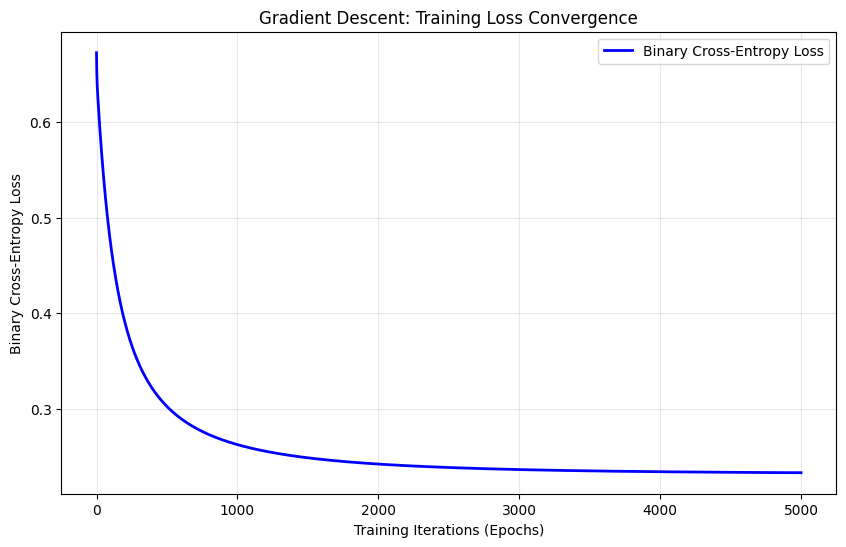

In [5]:

# Visualize loss reduction during Gradient Descent

plt.figure(figsize=(10, 6))

plt.plot(
    loss_history,
    color="blue",
    linewidth=2,
    label="Binary Cross-Entropy Loss"
)

plt.xlabel("Training Iterations (Epochs)")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Gradient Descent: Training Loss Convergence")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


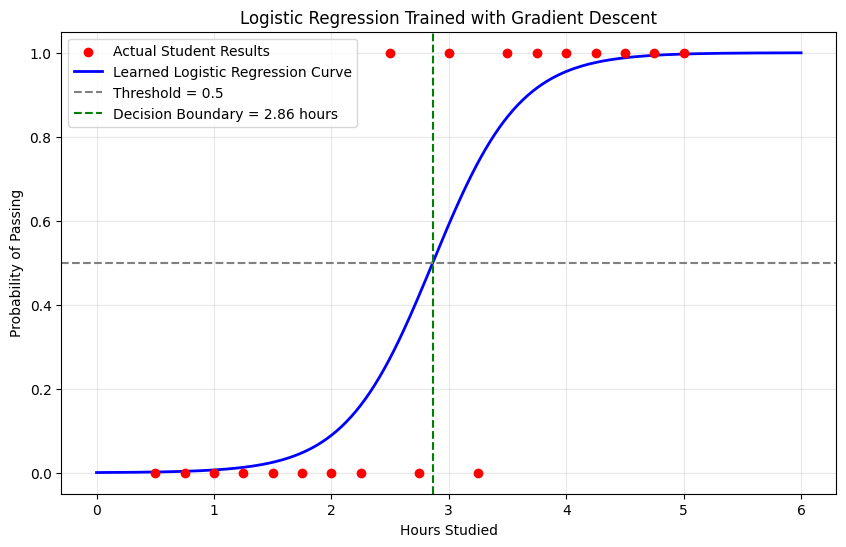

Decision Boundary: 2.8634 hours


In [6]:

# Visualize trained Logistic Regression classifier

# Generate study hours between 0 and 6
study_hours_range = np.linspace(0, 6, 300).reshape(-1, 1)

# Predicted probabilities from trained model
pass_probabilities = sigmoid(
    study_hours_range @ weights + bias
)

# Decision boundary where probability = 0.5
decision_boundary = -bias / weights[0]

plt.figure(figsize=(10, 6))

# Actual observations
plt.scatter(
    X.ravel(), y,
    color="red",
    label="Actual Student Results",
    zorder=3
)

# Learned sigmoid curve
plt.plot(
    study_hours_range.ravel(),
    pass_probabilities,
    color="blue",
    linewidth=2,
    label="Learned Logistic Regression Curve"
)

# Probability threshold
plt.axhline(
    0.5, color="gray", linestyle="--",
    label="Threshold = 0.5"
)

# Decision boundary
plt.axvline(
    decision_boundary,
    color="green",
    linestyle="--",
    label=f"Decision Boundary = {decision_boundary:.2f} hours"
)

plt.xlabel("Hours Studied")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression Trained with Gradient Descent")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Decision Boundary: {decision_boundary:.4f} hours")


### Results and Interpretation

The Logistic Regression model was successfully implemented
from scratch using NumPy and trained using Batch Gradient Descent.

**Training Results:**

- Optimized Weight: 2.6941
- Optimized Bias: -7.7143
- Loss after First Update: 0.6726
- Final Loss: 0.2332
- Training Accuracy: 89.47%
- Decision Boundary: approximately 2.86 study hours

**Observations:**

1. The Binary Cross-Entropy loss decreased steadily during
   training, which shows that Gradient Descent successfully
   optimized the model parameters.

2. The final loss value of 0.2332 is much lower than the
   initial loss, indicating improved model performance.

3. The model achieved a training accuracy of 89.47%,
   which means it correctly classified 17 out of 19 students.

4. The learned decision boundary is approximately 2.86 hours.
   This means the model predicts Pass when the estimated
   probability reaches 0.5 at around 2.86 study hours.

5. The learned sigmoid curve fits the training data well
   and clearly separates most Fail and Pass observations.

**Conclusion:**

The from-scratch implementation confirms that Logistic Regression
can model binary outcomes effectively by combining the sigmoid
function, Binary Cross-Entropy loss, and Gradient Descent.


## 5. Model Evaluation and Comparison with Scikit-learn

### Objective

The objective of this section is to evaluate our
Logistic Regression implementation and compare its
performance with scikit-learn's LogisticRegression.

We will compare:

1. Optimized weights and bias
2. Binary Cross-Entropy Loss
3. Classification Accuracy
4. Confusion Matrix
5. Predicted Pass/Fail outcomes

For a fair comparison, both models use the same dataset,
and we disable regularization in scikit-learn because
our from-scratch implementation does not use it.

Both models are evaluated on their training data.
Therefore, the results demonstrate how well the models
fit the available observations, not their performance
on unseen students.


In [7]:

# Step 5: Compare our model with Scikit-learn

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    confusion_matrix
)

# 1. Create the Scikit-learn model
# Disable regularization to match our implementation
sk_model = LogisticRegression(
    penalty=None,
    max_iter=10000
)

# 2. Train on the professor's dataset
sk_model.fit(X, y)

# 3. Predict probabilities and classes
sk_probabilities = sk_model.predict_proba(X)[:, 1]
sk_predictions = sk_model.predict(X)

# 4. Evaluate Scikit-learn
sk_accuracy = accuracy_score(y, sk_predictions)
sk_loss = log_loss(y, sk_probabilities)

# 5. Evaluate our from-scratch model
scratch_accuracy = accuracy_score(y, predicted_classes)

scratch_loss = binary_cross_entropy(
    y, predicted_probabilities
)

# 6. Compare results
print("=== MODEL COMPARISON ===")

print("\n1. From-Scratch Logistic Regression")
print(f"Weight: {weights[0]:.4f}")
print(f"Bias: {bias:.4f}")
print(f"Accuracy: {scratch_accuracy * 100:.2f}%")
print(f"Log-Loss: {scratch_loss:.4f}")

print("\n2. Scikit-learn Logistic Regression")
print(f"Weight: {sk_model.coef_[0][0]:.4f}")
print(f"Bias: {sk_model.intercept_[0]:.4f}")
print(f"Accuracy: {sk_accuracy * 100:.2f}%")
print(f"Log-Loss: {sk_loss:.4f}")

# 7. Confusion matrices
print("\n=== CONFUSION MATRICES ===")

print("\nFrom-Scratch Model:")
print(confusion_matrix(y, predicted_classes))

print("\nScikit-learn Model:")
print(confusion_matrix(y, sk_predictions))


=== MODEL COMPARISON ===

1. From-Scratch Logistic Regression
Weight: 2.6941
Bias: -7.7143
Accuracy: 89.47%
Log-Loss: 0.2332

2. Scikit-learn Logistic Regression
Weight: 2.9703
Bias: -8.5400
Accuracy: 89.47%
Log-Loss: 0.2321

=== CONFUSION MATRICES ===

From-Scratch Model:
[[9 1]
 [1 8]]

Scikit-learn Model:
[[9 1]
 [1 8]]



### Results and Interpretation

The Logistic Regression implementation developed from scratch
was compared with scikit-learn's LogisticRegression model.

Both models were trained and evaluated using the same
19-student dataset.

**Model Comparison Results:**

| Metric | From Scratch | Scikit-learn |
|---|---:|---:|
| Weight | 2.6941 | 2.9703 |
| Bias | -7.7143 | -8.5400 |
| Accuracy | 89.47% | 89.47% |
| Binary Cross-Entropy Loss | 0.2332 | 0.2321 |

### Observations

1. Both models achieved a training accuracy of 89.47%,
   correctly classifying 17 out of 19 students.

2. Scikit-learn achieved a slightly lower log-loss of
   0.2321 compared with our implementation's 0.2332.

3. The optimized weights and biases are slightly different
   because our implementation uses a fixed number of
   Gradient Descent iterations, while scikit-learn uses
   a different optimization algorithm.

4. Both models produced the same confusion matrix:

   - True Negatives (TN): 9
   - False Positives (FP): 1
   - False Negatives (FN): 1
   - True Positives (TP): 8

5. The matching classifications and similar loss values
   provide evidence that our from-scratch implementation
   is functioning correctly.

### Limitations

The dataset contains only 19 observations, and both models
were evaluated on the same data used for training.

Therefore, the reported accuracy represents training
performance and does not establish how well the models
will generalize to new students.

A larger dataset with a separate test set would provide
a more reliable evaluation of generalization performance.

### Conclusion

Our Logistic Regression implementation successfully
learned the relationship between study hours and
Pass/Fail outcomes using the sigmoid function,
Binary Cross-Entropy loss, and Gradient Descent.

The comparison with scikit-learn supports the correctness
of our implementation.



## 6. Three Technical Talking Points

### Talking Point 1: Sigmoid Function and Binary Classification

**What does this code do?**

The sigmoid function converts a linear combination of study
hours, weight, and bias into a probability between 0 and 1.

**Relevant Code:**

```python
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
```

**Mathematical Formula:**

$$
\sigma(z) = \frac{1}{1+e^{-z}}
$$

where $z = wx+b$.

**Why is it important?**

Logistic Regression uses the sigmoid function to estimate
the probability of a student passing an examination.

- Probability >= 0.5: Predict Pass (1).
- Probability < 0.5: Predict Fail (0).

**Observation from Our Implementation:**

After training, the learned decision boundary was
approximately 2.86 study hours.

**Key Learning:**

The sigmoid function allows Logistic Regression to
convert continuous numerical outputs into probabilities
suitable for binary classification.

---

### Talking Point 2: Binary Cross-Entropy Loss

**What does this code do?**

Binary Cross-Entropy measures how accurately the
predicted probabilities match the actual Pass/Fail labels.

**Relevant Code:**

```python
def binary_cross_entropy(y_true, y_prob):
    epsilon = 1e-15

    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()

    y_prob = np.clip(y_prob, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_prob)
        + (1 - y_true) * np.log(1 - y_prob)
    )

    return loss
```

**Mathematical Formula:**

$$
J = -\frac{1}{m}\sum_{i=1}^{m}
[y_i\log(p_i)+(1-y_i)\log(1-p_i)]
$$

**Why is it important?**

Binary Cross-Entropy assigns a higher penalty to
confidently incorrect predictions.

**Observation from Our Implementation:**

- Good Prediction Loss: 0.1054
- Bad Prediction Loss: 2.3026

The bad prediction received a much larger penalty.

**Key Learning:**

Minimizing Binary Cross-Entropy encourages the model
to produce more accurate predicted probabilities.

---

### Talking Point 3: Gradient Descent and Model Training

**What does this code do?**

Gradient Descent updates the model's weight and bias
to minimize Binary Cross-Entropy Loss.

**Relevant Code:**

```python
# Calculate prediction error
error = predictions - y

# Calculate gradients
dw = (X.T @ error) / m
db = np.mean(error)

# Update model parameters
weights -= learning_rate * dw
bias -= learning_rate * db
```

**Mathematical Formulas:**

Weight update:

$$
w_{\text{new}} =
w-\alpha\frac{\partial J}{\partial w}
$$

Bias update:

$$
b_{\text{new}} =
b-\alpha\frac{\partial J}{\partial b}
$$

where $\alpha$ is the learning rate.

**Why is it important?**

Gradient Descent helps the model learn from errors
and improve predictions over repeated iterations.

**Observation from Our Implementation:**

- Training Iterations: 5000
- Optimized Weight: 2.6941
- Optimized Bias: -7.7143
- Loss after First Update: 0.6726
- Final Loss: 0.2332
- Training Accuracy: 89.47%

The loss convergence graph showed that the loss
decreased and gradually stabilized during training.

**Key Learning:**

Gradient Descent successfully optimized the
Logistic Regression parameters using vectorized
NumPy operations without relying on scikit-learn
for model training.

---

### Overall Reflection

These three components work together:

1. The sigmoid function calculates the predicted
   probability of passing.
2. Binary Cross-Entropy measures the prediction error.
3. Gradient Descent updates the model's parameters
   to minimize that error.

Our implementation achieved 89.47% training accuracy,
correctly classifying 17 out of 19 students.

Comparing our implementation with scikit-learn provided
additional evidence that the algorithm was implemented
correctly.

However, evaluation on unseen data would be needed
to assess generalization performance.



## 7. Peer Programming and Code Review

### 7.1 Participating Teams

**Our Team:** Final_Project_Group 2

**Our GitHub Repository:**

https://github.com/UbaidUllah777/LogisticRegressionClassifier_Workshop.git

**Peer Team:** kinghighshow (Team A)

**Peer GitHub Repository:**

https://github.com/kinghighshow/LogisticRegressionClassifierWorkshop.git

**Notebook Reviewed:** PairProgrammingReport.ipynb

---

### 7.2 Review of the Peer Team's Implementation

We examined the peer team's GitHub notebook to
understand their implementation of Logistic Regression,
Binary Cross-Entropy, and Gradient Descent.

**Observation 1: Object-Oriented Implementation**

The peer team implemented Logistic Regression using
a Python class named LogisticRegressionScratch.

The class includes methods for:

- Training the model using Gradient Descent.
- Predicting probabilities.
- Predicting Pass/Fail classifications.
- Calculating the decision boundary.

Our implementation uses separate Python functions
for training, prediction, and loss calculation.

Both approaches implement Logistic Regression
from scratch using NumPy.

**Observation 2: Learning Rate Comparison**

The peer team experimented with three learning rates:

- 0.01
- 0.1
- 0.5

Their notebook demonstrates how the learning rate
affects the speed of Gradient Descent convergence.

Our implementation uses a learning rate of 0.1
with 5,000 training iterations.

This comparison highlights the importance of
selecting suitable hyperparameters.

**Observation 3: Model Evaluation**

The peer team's model achieved approximately:

- Training Accuracy: 89.47%
- Final Log-Loss: 0.2321
- Decision Boundary: 2.88 hours

Our implementation achieved:

- Training Accuracy: 89.47%
- Final Log-Loss: 0.2332
- Decision Boundary: 2.86 hours

Both implementations used the same 19-student
dataset and produced similar results.

**Observation 4: Additional Visualizations**

The peer team's notebook uses Plotly to display
interactive graphs for:

- Logistic Regression probabilities.
- Gradient Descent convergence.
- Learning rate comparisons.
- Confusion matrix.
- Individual student Log-Loss.
- Accuracy versus Log-Loss.

Our notebook uses Matplotlib to visualize
the sigmoid function, Log-Loss curves,
training convergence, and decision boundary.

Both visualization approaches help explain
the model's behavior.

---

### 7.3 Technical Feedback Prepared for the Peer Team

**Strengths:**

1. The object-oriented structure clearly separates
   model training and prediction functionality.

2. The learning rate comparison makes it easier
   to understand Gradient Descent optimization.

3. The additional visualizations help explain why
   model accuracy alone does not describe the
   quality of predicted probabilities.

**Suggested Improvements:**

1. Include an evaluation on unseen data when a
   sufficiently large dataset is available.

2. Document how the custom model class could be
   extended to support multiple input features.

3. Complete the peer-programming session notes
   with actual questions, answers, and reflections.

These points are based on the published notebook
and can be discussed during the peer review.

---


### 7.4 Questions We Asked the Peer Team

We exchanged technical questions with Team A after
reviewing their implementation.

**Question 1: Why use a learning rate of 0.5?**

The peer team tested learning rates of 0.01, 0.1,
and 0.5 over 5,000 training iterations.

**Their Answer:**

- At 0.01, the final loss remained around 0.30.
- At 0.1, the final loss reached 0.2332.
- At 0.5, the loss approached 0.2321, matching
  scikit-learn more closely.

They explained that 0.5 converged faster on this
small dataset. Larger feature values might require
feature scaling or a smaller learning rate.

**Question 2: Why use a class instead of functions?**

**Their Answer:**

Their LogisticRegressionScratch class organizes the
model's parameters, training history, and methods
in one place.

It provides fit(), predict_proba(), and predict()
methods similar to scikit-learn.

This also makes testing multiple learning rates
and comparing models more convenient.

**Question 3: How would you evaluate unseen students?**

**Their Answer:**

Because the dataset has only 19 students, the
peer team suggested leave-one-out cross-validation.

This involves training on 18 students and
testing on the remaining student, repeating
the process 19 times.

With a larger dataset, they suggested a stratified
train-test split and evaluation using Log-Loss
and a confusion matrix.

---

### 7.5 Peer Team's Review of Our Code

Team A reviewed our NumPy implementation and asked
three technical questions.

**Question 1: Did our model finish learning?**

They noticed that our optimized weights differed
slightly from scikit-learn's weights.

They suggested that the difference might result
from incomplete convergence rather than only
the choice of optimizer.

**Our Response:**

Our model uses a learning rate of 0.1 with
5,000 iterations.

The final training loss is 0.2332, compared with
scikit-learn's 0.2321.

A comparison using a learning rate of 0.5 on
the same dataset produces a loss near 0.2321
and weights closer to scikit-learn.

This indicates that our original model had not
fully converged after 5,000 iterations.

We learned that the learning rate and number of
iterations both affect convergence.

**Question 2: Is our sigmoid function numerically stable?**

The peer team pointed out that our sigmoid
implementation does not limit extreme input values.

**Our Response:**

For a very negative input z, the expression
np.exp(-z) can overflow and produce a warning.

Although the mathematical sigmoid approaches zero,
the direct calculation may become numerically
unstable.

We can improve our implementation by clipping
z to a safe range before applying the exponential:

    z = np.clip(z, -500, 500)

This is an important improvement for numerical
stability, especially with extreme input values.

**Question 3: Why do we calculate loss after every update?**

The peer team noticed that our first recorded
loss is 0.6726 rather than the initial value 0.6931.

They also observed that our method calculates
predictions again after each parameter update.

**Our Response:**

We calculated the loss after each weight update
to measure the performance of the newly updated
model parameters.

Therefore, the first recorded loss of 0.6726
represents the loss after the first update.

The actual starting loss before training is
approximately 0.6931 because the initial weights
and bias are zero, giving a probability of 0.5.

We recognize that recalculating predictions
after every update creates additional work.

A more efficient approach is to record the loss
using the probabilities already calculated
before updating the parameters.

This would record the starting loss and reduce
repeated calculations.

---

### 7.6 Peer Programming Reflections

Reviewing the other team's implementation helped
us understand several important concepts.

**1. Gradient Descent Convergence**

We learned that using a fixed number of iterations
does not guarantee that Gradient Descent has fully
converged.

The comparison of learning rates showed why the
choice of step size matters.

**2. Numerical Stability**

The peer review identified a limitation in our
sigmoid implementation.

Clipping extreme input values is a simple way
to reduce overflow warnings.

**3. Efficient Training**

We learned that calculating the loss after each
parameter update can require an additional
forward calculation.

Recording loss before the update is another
valid approach that can improve efficiency.

**4. Software Design**

The other team used an object-oriented
implementation, while we used separate functions.

Both approaches are valid, but the class-based
design provides better organization when managing
multiple model instances and configurations.

**5. Model Evaluation**

Both teams achieved 89.47% training accuracy.

However, we recognized that training accuracy
alone is insufficient to evaluate performance
on unseen students.

Leave-one-out cross-validation could be
explored in future work.

### Conclusion

The peer review helped us better understand
convergence, numerical stability, training
efficiency, and code organization.

It also demonstrated the importance of
reviewing different implementations of the
same machine learning algorithm.

Our Logistic Regression implementation is
functioning correctly on the training data,
and the feedback identified opportunities
for further improvement.
